## Test plotting for connectivity matrixes
A code to import the connectivity matrix values from pdf_plots_matrix_nodataframe_onlymatrix.py etc. and plot the results before adapting this code into the afformentioned python script for faster plotting for probability density plots and connectivity matrices.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm

In [1]:
#This is a matrix whose entries represent Gaussian KDE density evaluated at target vent locations, 
#used as relative connectivity weights between source and target vents.

# === Load your data ===
conn = pd.read_csv(
    "pdf_plots/previous_connectivity_matrix_reordered_num_depth_3d_multipl2_multidepth_maxdepth_100minterval_60d_30r.csv", 
    index_col=0
)
vals = conn.values

# === Choose normalization (log if range > 1e4) ===
pos = vals[vals > 0]
use_log = pos.size and (np.nanmax(vals) / max(np.nanmin(pos), 1e-30) > 1e4)
if use_log:
    vmin = max(pos.min(), 1e-16)
    norm = LogNorm(vmin=vmin, vmax=vals.max())
else:
    norm = Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))

# === Choose colormap ===
cmap = 'Blues'  # dark blue = high

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(vals, aspect='equal', norm=norm, cmap=cmap) #used if using normalization

# === Colorbar ===
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Probability Density per square degree")#" + (" (log scale)" if use_log else ""))

# === Axes ===
ax.set_xticks(np.arange(conn.shape[1]), labels=conn.columns, rotation=60, ha="right")
ax.set_yticks(np.arange(conn.shape[0]), labels=conn.index)
ax.set_xlabel("Target vent")
ax.set_ylabel("Source vent")
ax.set_title("Indian Ocean Vent Gaussian KDE density connectivity matrix")

# === Format numbers with forced line breaks ===
# def fmt_multiline(x):
#     """Formats numbers like 3.2e+05 → '3.2\\ne+05' for multiline display."""
#     if not np.isfinite(x) or x == 0:
#         return "–"
#     if use_log or (x < 1e-3 or x >= 1e3):
#         #s = f"{x:.1e}"  # e.g. '3.2e+05'
#         s = f"{x:.2e}"  # e.g. '3.24e+05'
#         base, exp = s.split("e")  # base='3.2', exp='+05'
#         return f"{base}\ne{exp}"  # new line before 'e+05'
#     else:
#         return f"{x:.3f}"

def fmt_multiline(x):
    """Formats numbers like 3.2e+05 → '3.2\\ne+05' for multiline display. Except e±3"""
    if not np.isfinite(x) or x == 0:
        return "–"
    if abs(x) < 1e-3 or abs(x) >= 1e3:
        #s = f"{x:.1e}"  # e.g. '3.2e+05'
        s = f"{x:.2e}"  # e.g. '3.24e+05'
        base, exp = s.split("e")
        return f"{base}\ne{exp}"
    return f"{x:.3f}"

# === Annotate with smaller text, allow wrapping ===
for i in range(conn.shape[0]):
    for j in range(conn.shape[1]):
        v = vals[i, j]
        rgba = im.cmap(im.norm(v if np.isfinite(v) else 0.0))
        L = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        color = "white" if L < 0.45 else "black"
        ax.text(
            j, i, fmt_multiline(v),
            ha="center", va="center",
            color=color,
            fontsize=10.5, linespacing=0.9
        )


# === Subtle gridlines ===
ax.set_xticks(np.arange(-.5, conn.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, conn.shape[0], 1), minor=True)
ax.grid(which="minor", color="#e0e0e0", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout(pad=1.0)
# plt.savefig("pdf_plots/connectivity_matrix_blues.png", dpi=300)
# plt.savefig("pdf_plots/connectivity_matrix_blues.pdf")
plt.show()


NameError: name 'pd' is not defined

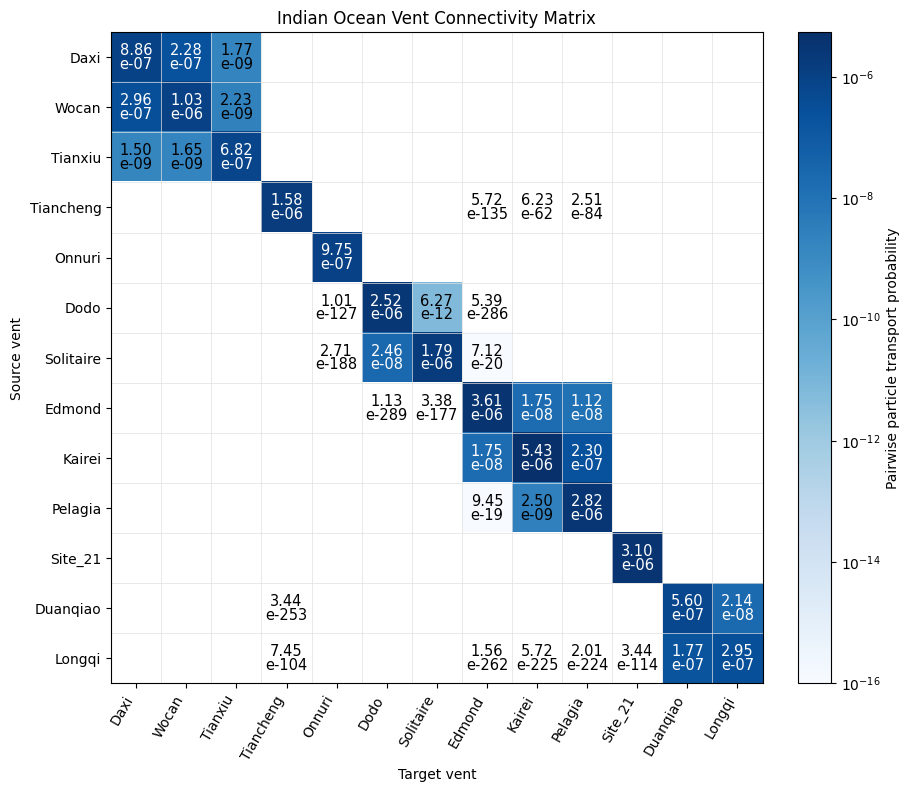

In [2]:
#This is a matrix whose entries represent Gaussian KDE density evaluated at target vent locations INTEGRATED over space (100m2), 
#to give probability mass used as connectivity measure between source and target vents.

# === Load your data ===
conn = pd.read_csv(
    "pdf_plots/Otisintegral_debugging_connectivity_matrix_reordered_num_depth_3d_multipl2_multidepth_maxdepth_100minterval_60d_30r.csv", 
    index_col=0
)
vals = conn.values

# === Choose normalization (log if range > 1e4) ===
pos = vals[vals > 0]
use_log = pos.size and (np.nanmax(vals) / max(np.nanmin(pos), 1e-30) > 1e4)
if use_log:
    vmin = max(pos.min(), 1e-16)
    norm = LogNorm(vmin=vmin, vmax=vals.max())
else:
    norm = Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))

# === Choose colormap ===
cmap = 'Blues'  # dark blue = high

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(vals, aspect='equal', norm=norm, cmap=cmap) #used if using normalization

# === Colorbar ===
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pairwise particle transport probability")#" + (" (log scale)" if use_log else ""))

# === Axes ===
ax.set_xticks(np.arange(conn.shape[1]), labels=conn.columns, rotation=60, ha="right")
ax.set_yticks(np.arange(conn.shape[0]), labels=conn.index)
ax.set_xlabel("Target vent")
ax.set_ylabel("Source vent")
ax.set_title("Indian Ocean Vent Connectivity Matrix")

# === Format numbers with forced line breaks ===
# def fmt_multiline(x):
#     """Formats numbers like 3.2e+05 → '3.2\\ne+05' for multiline display."""
#     if not np.isfinite(x) or x == 0:
#         return "–"
#     if use_log or (x < 1e-3 or x >= 1e3):
#         #s = f"{x:.1e}"  # e.g. '3.2e+05'
#         s = f"{x:.2e}"  # e.g. '3.24e+05'
#         base, exp = s.split("e")  # base='3.2', exp='+05'
#         return f"{base}\ne{exp}"  # new line before 'e+05'
#     else:
#         return f"{x:.3f}"

def fmt_multiline(x):
    """Formats numbers like 3.2e+05 → '3.2\\ne+05' for multiline display. Except e±3"""
    if not np.isfinite(x) or x == 0:
        return "–"
    if abs(x) < 1e-3 or abs(x) >= 1e3:
        #s = f"{x:.1e}"  # e.g. '3.2e+05'
        s = f"{x:.2e}"  # e.g. '3.24e+05'
        base, exp = s.split("e")
        return f"{base}\ne{exp}"
    return f"{x:.3f}"

# === Annotate with smaller text, allow wrapping ===
for i in range(conn.shape[0]):
    for j in range(conn.shape[1]):
        v = vals[i, j]
        rgba = im.cmap(im.norm(v if np.isfinite(v) else 0.0))
        L = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        color = "white" if L < 0.45 else "black"
        ax.text(
            j, i, fmt_multiline(v),
            ha="center", va="center",
            color=color,
            fontsize=10.5, linespacing=0.9
        )


# === Subtle gridlines ===
ax.set_xticks(np.arange(-.5, conn.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, conn.shape[0], 1), minor=True)
ax.grid(which="minor", color="#e0e0e0", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout(pad=1.0)
# plt.savefig("pdf_plots/connectivity_matrix_blues.png", dpi=300)
# plt.savefig("pdf_plots/connectivity_matrix_blues.pdf")
plt.show()


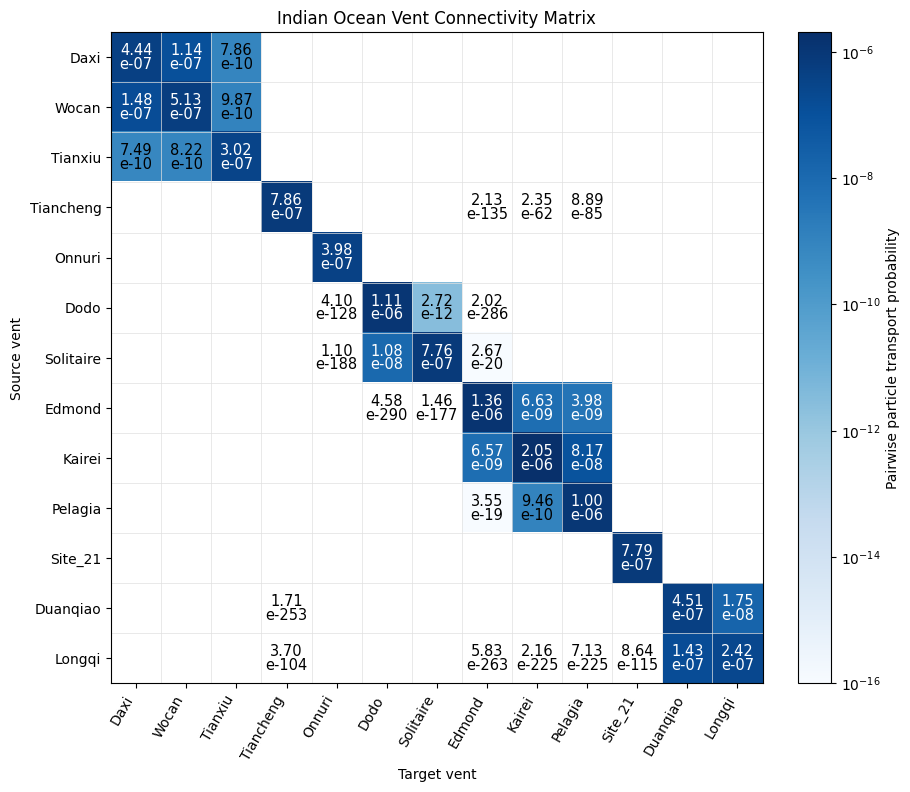

In [3]:

#This is a matrix whose entries represent Gaussian KDE density evaluated at target vent locations INTEGRATED over space (100m2), 
#to give probability mass used as connectivity measure between source and target vents.

# === Load your data ===
conn = pd.read_csv(
    "pdf_plots/complete_s_100_connectivity_matrix_reordered_num_depth_3d_multipl2_multidepth_maxdepth_100minterval_60d_30r.csv", 
    index_col=0
)
vals = conn.values

# === Choose normalization (log if range > 1e4) ===
pos = vals[vals > 0]
use_log = pos.size and (np.nanmax(vals) / max(np.nanmin(pos), 1e-30) > 1e4)
if use_log:
    vmin = max(pos.min(), 1e-16)
    norm = LogNorm(vmin=vmin, vmax=vals.max())
else:
    norm = Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))

# === Choose colormap ===
cmap = 'Blues'  # dark blue = high

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(vals, aspect='equal', norm=norm, cmap=cmap) #used if using normalization

# === Colorbar ===
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pairwise particle transport probability")#" + (" (log scale)" if use_log else ""))

# === Axes ===
ax.set_xticks(np.arange(conn.shape[1]), labels=conn.columns, rotation=60, ha="right")
ax.set_yticks(np.arange(conn.shape[0]), labels=conn.index)
ax.set_xlabel("Target vent")
ax.set_ylabel("Source vent")
ax.set_title("Indian Ocean Vent Connectivity Matrix")

# === Format numbers with forced line breaks ===
# def fmt_multiline(x):
#     """Formats numbers like 3.2e+05 → '3.2\\ne+05' for multiline display."""
#     if not np.isfinite(x) or x == 0:
#         return "–"
#     if use_log or (x < 1e-3 or x >= 1e3):
#         #s = f"{x:.1e}"  # e.g. '3.2e+05'
#         s = f"{x:.2e}"  # e.g. '3.24e+05'
#         base, exp = s.split("e")  # base='3.2', exp='+05'
#         return f"{base}\ne{exp}"  # new line before 'e+05'
#     else:
#         return f"{x:.3f}"

def fmt_multiline(x):
    """Formats numbers like 3.2e+05 → '3.2\\ne+05' for multiline display. Except e±3"""
    if not np.isfinite(x) or x == 0:
        return "–"
    if abs(x) < 1e-3 or abs(x) >= 1e3:
        #s = f"{x:.1e}"  # e.g. '3.2e+05'
        s = f"{x:.2e}"  # e.g. '3.24e+05'
        base, exp = s.split("e")
        return f"{base}\ne{exp}"
    return f"{x:.3f}"

# === Annotate with smaller text, allow wrapping ===
for i in range(conn.shape[0]):
    for j in range(conn.shape[1]):
        v = vals[i, j]
        rgba = im.cmap(im.norm(v if np.isfinite(v) else 0.0))
        L = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        color = "white" if L < 0.45 else "black"
        ax.text(
            j, i, fmt_multiline(v),
            ha="center", va="center",
            color=color,
            fontsize=10.5, linespacing=0.9
        )


# === Subtle gridlines ===
ax.set_xticks(np.arange(-.5, conn.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, conn.shape[0], 1), minor=True)
ax.grid(which="minor", color="#e0e0e0", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout(pad=1.0)
# plt.savefig("pdf_plots/connectivity_matrix_blues.png", dpi=300)
# plt.savefig("pdf_plots/connectivity_matrix_blues.pdf")
plt.show()


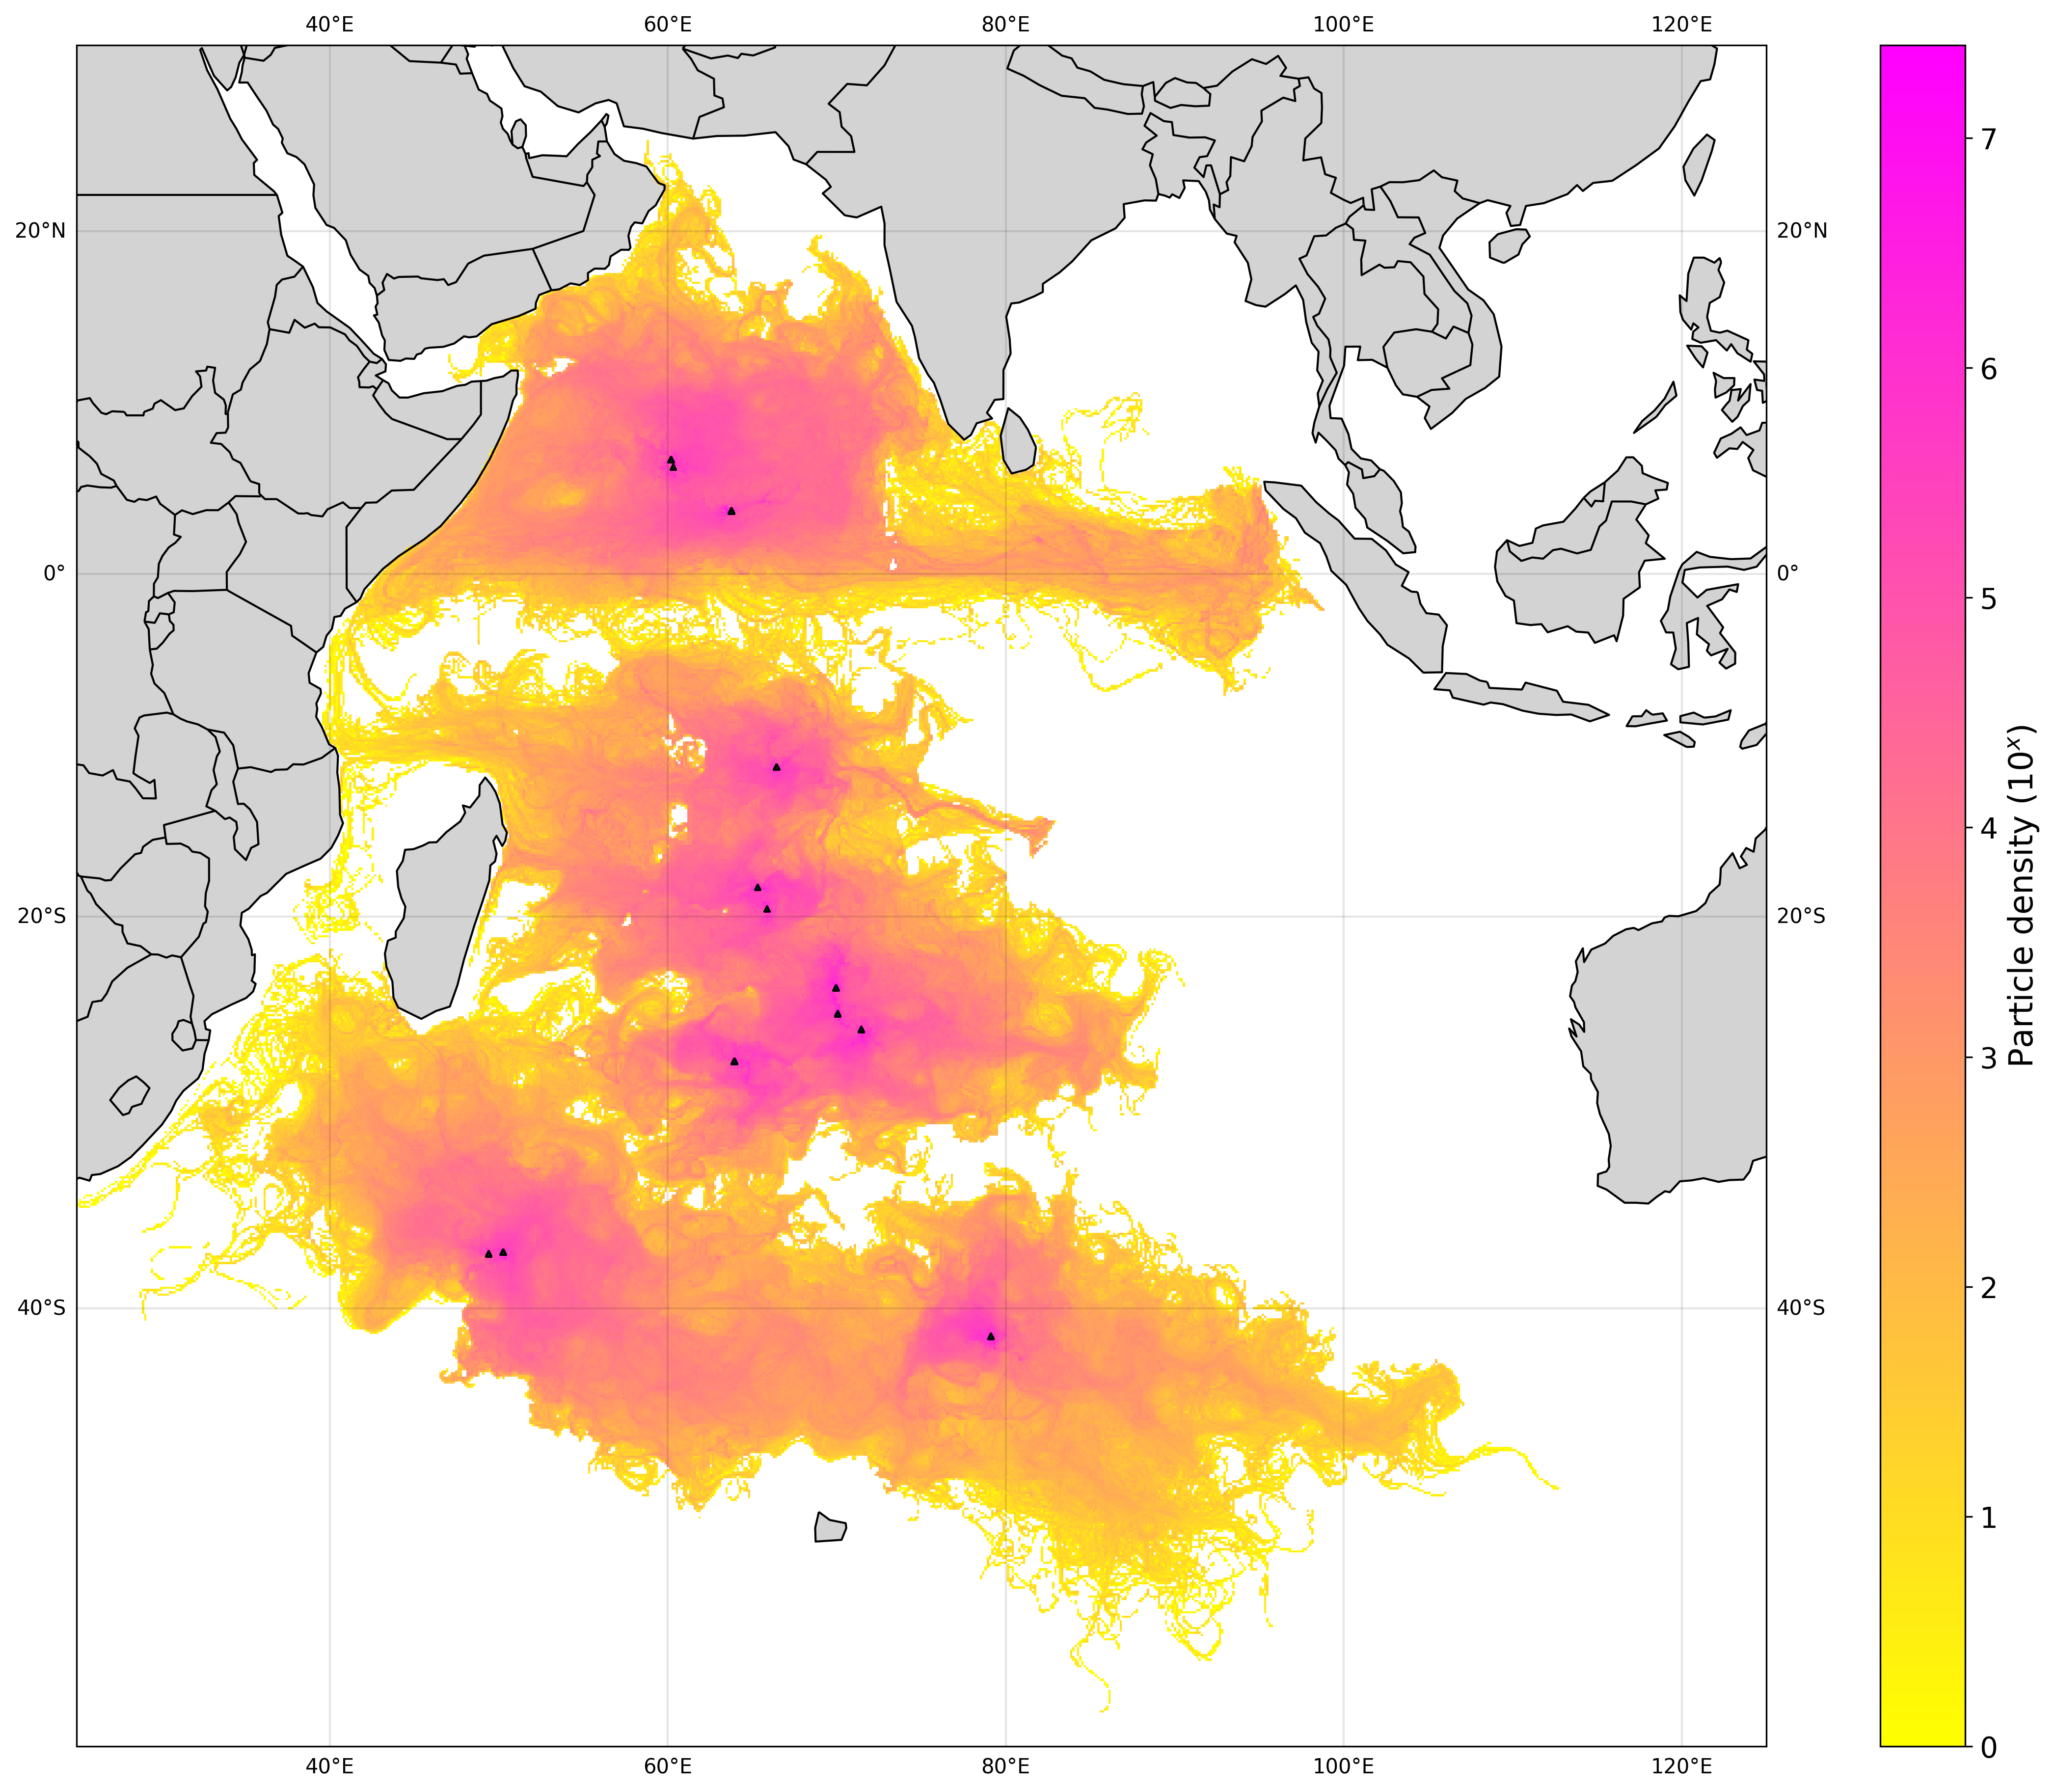

In [4]:
from IPython.display import Image, display

display(Image(filename="plots/densityplot_reordered_num_depth_3d_multipl100_multidepth_maxdepth_100minterval_150d_75r.png"))


In [ ]:
display(Image(filename="../2D_multip_multidepth/plots/densityplot_reordered_num_depth_3d_multipl100_multidepth_maxdepth_100minterval_150d_75r.png"))



# Connectivity plots

In [1]:
# For connectivity prob matrix
import pandas as pd
from matplotlib.colors import Normalize, LogNorm

# For connectivity map plots
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.patches import FancyArrowPatch
from matplotlib.path import Path
import cmocean
import netCDF4 as nc
import xarray as xr

## Connectivity matrix

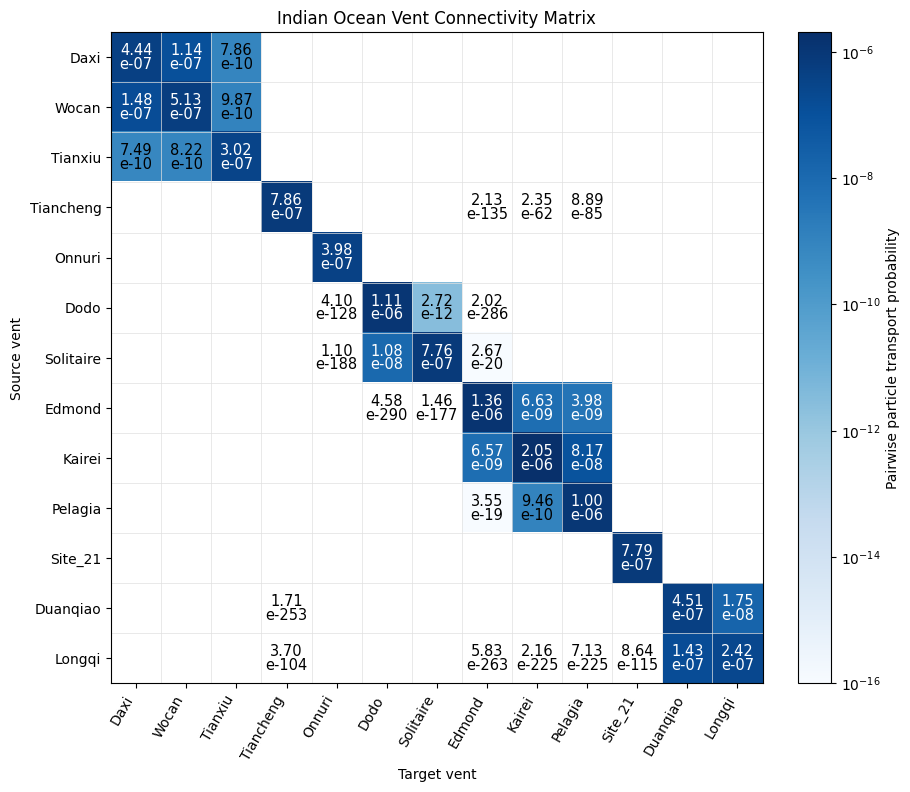

In [2]:
#This is a matrix whose entries represent Gaussian KDE density evaluated at target vent locations INTEGRATED over space (100m2), 
#to give probability mass used as connectivity measure between source and target vents.

# === Load your data ===
conn = pd.read_csv(
    "pdf_plots/complete_s_100_connectivity_matrix_reordered_num_depth_3d_multipl2_multidepth_maxdepth_100minterval_60d_30r.csv", 
    index_col=0
)
vals = conn.values

# === Choose normalization (log if range > 1e4) ===
pos = vals[vals > 0]
use_log = pos.size and (np.nanmax(vals) / max(np.nanmin(pos), 1e-30) > 1e4)
if use_log:
    vmin = max(pos.min(), 1e-16)
    norm = LogNorm(vmin=vmin, vmax=vals.max())
else:
    norm = Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))

# === Choose colormap ===
cmap = 'Blues'  # dark blue = high

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(vals, aspect='equal', norm=norm, cmap=cmap) #used if using normalization

# === Colorbar ===
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pairwise particle transport probability")#" + (" (log scale)" if use_log else ""))

# === Axes ===
ax.set_xticks(np.arange(conn.shape[1]), labels=conn.columns, rotation=60, ha="right")
ax.set_yticks(np.arange(conn.shape[0]), labels=conn.index)
ax.set_xlabel("Target vent")
ax.set_ylabel("Source vent")
ax.set_title("Indian Ocean Vent Connectivity Matrix")

# === Format numbers with forced line breaks ===
# def fmt_multiline(x):
#     """Formats numbers like 3.2e+05 → '3.2\\ne+05' for multiline display."""
#     if not np.isfinite(x) or x == 0:
#         return "–"
#     if use_log or (x < 1e-3 or x >= 1e3):
#         #s = f"{x:.1e}"  # e.g. '3.2e+05'
#         s = f"{x:.2e}"  # e.g. '3.24e+05'
#         base, exp = s.split("e")  # base='3.2', exp='+05'
#         return f"{base}\ne{exp}"  # new line before 'e+05'
#     else:
#         return f"{x:.3f}"

def fmt_multiline(x):
    """Formats numbers like 3.2e+05 → '3.2\\ne+05' for multiline display. Except e±3"""
    if not np.isfinite(x) or x == 0:
        return "–"
    if abs(x) < 1e-3 or abs(x) >= 1e3:
        #s = f"{x:.1e}"  # e.g. '3.2e+05'
        s = f"{x:.2e}"  # e.g. '3.24e+05'
        base, exp = s.split("e")
        return f"{base}\ne{exp}"
    return f"{x:.3f}"

# === Annotate with smaller text, allow wrapping ===
for i in range(conn.shape[0]):
    for j in range(conn.shape[1]):
        v = vals[i, j]
        rgba = im.cmap(im.norm(v if np.isfinite(v) else 0.0))
        L = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        color = "white" if L < 0.45 else "black"
        ax.text(
            j, i, fmt_multiline(v),
            ha="center", va="center",
            color=color,
            fontsize=10.5, linespacing=0.9
        )


# === Subtle gridlines ===
ax.set_xticks(np.arange(-.5, conn.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, conn.shape[0], 1), minor=True)
ax.grid(which="minor", color="#e0e0e0", linestyle="-", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout(pad=1.0)
# plt.savefig("pdf_plots/connectivity_matrix_blues.png", dpi=300)
# plt.savefig("pdf_plots/connectivity_matrix_blues.pdf")
plt.show()


## Connectivity maps

In [3]:
prob_conn = conn

In [4]:
# Get vent names
excel_file_path = '/flash/MitaraiU/oceanparcels/htv/lily/indianocean_accurate_perez2021_fields.xlsx' #indianocean_perez2021_fields.xlsx' 

vent_sites = pd.read_excel(excel_file_path,index_col = 'Vent Name')
vent_sites['name']=vent_sites.index.str.replace(" ", "_")
v_name=vent_sites.name[0]
vent_sites

/scratch/ipykernel_1543357/1999020648.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  v_name=vent_sites.name[0]


,Latitude,Longitude,Depth (m),Ridge,name
Vent Name,,,,,
Daxi,6.8000,60.1800,3450,CR,Daxi
Wocan,6.3630,60.3030,2989,CR,Wocan
Tianxiu,3.7500,63.7500,3450,CR,Tianxiu
Tiancheng,-27.8508,63.9227,2705,SWIR,Tiancheng
Onnuri,-11.4147,66.4230,2022,CIR,Onnuri
Dodo,-18.3365,65.2990,2745,CIR,Dodo
Solitaire,-19.5569,65.8478,2606,CIR,Solitaire
Edmond,-23.9183,69.9387,3290–3320,CIR,Edmond
Kairei,-25.3195,70.0405,2422-2450,CIR,Kairei


In [5]:
# Get bathymetry files 
data_path_MERC = '/bucket/MitaraiU/Users/heng/GLORYS12/'
# Load landmask and bathymetry
mask_bathy_path = data_path_MERC + 'GLO-MFC_001_024_mask_bathy.nc' 
mask_bathy      = nc.Dataset(mask_bathy_path)
landmask = mask_bathy['mask']  # dim=(depth=50, lat=2041, lon=4320); Land: 0, Ocean: 1
# Make negative of land mask (i.e. Land: 1, Ocean: 0)
landmask_negative = 1 - landmask[:]
# Load coordinates file
mesh_mask_path = data_path_MERC + 'GLO-MFC_001_024_coordinates.nc' 
mesh_mask      = nc.Dataset(mesh_mask_path)

seafloor = xr.open_mfdataset(mask_bathy_path)

In [46]:
# label offsets

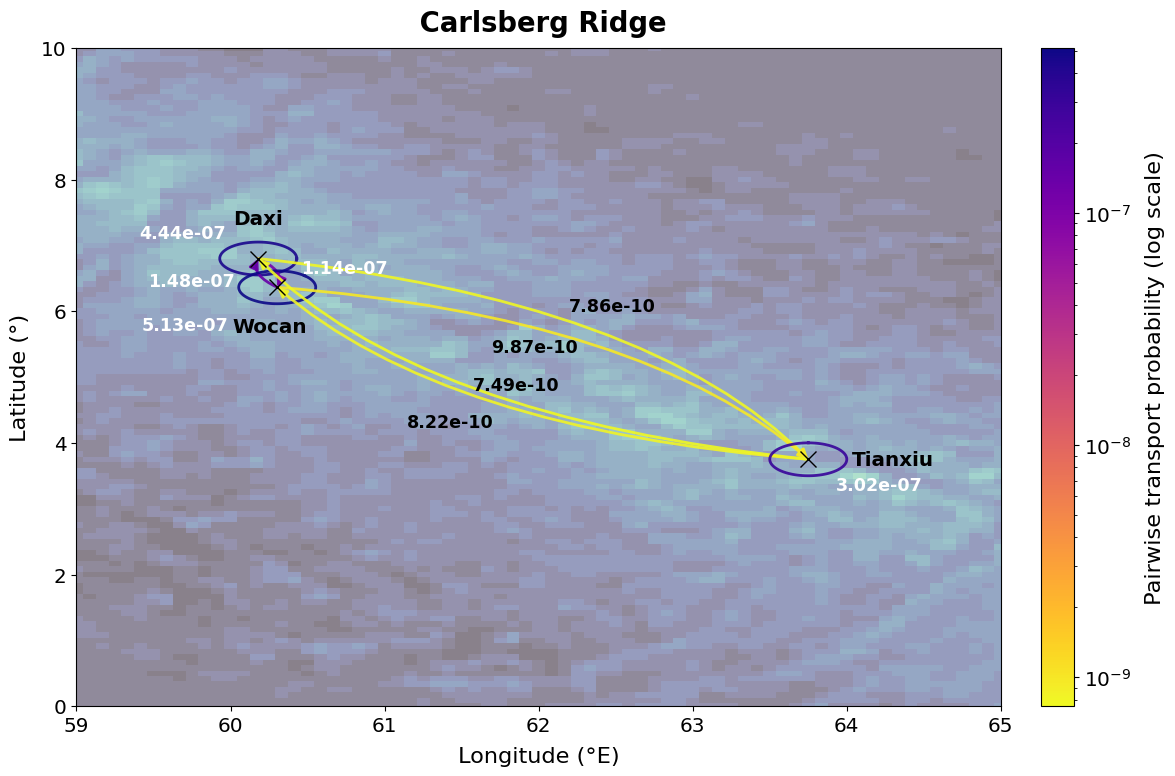

In [6]:
# ===================== CONFIG =====================
font_scale = 1.8
plt.rcParams.update({
    "font.size": 8 * font_scale,
    "axes.titlesize": 10 * font_scale,
    "axes.labelsize": 9 * font_scale,
    "xtick.labelsize": 8 * font_scale,
    "ytick.labelsize": 8 * font_scale,
    "legend.fontsize": 8 * font_scale,
    "figure.titlesize": 12 * font_scale
})

region_bounds = {
    "name": "Carlsberg Ridge",
    "lat_min": 0, "lat_max": 10,
    "lon_min": 59, "lon_max": 65
}

# ===================== DATA FILTERING =====================
lon_min, lon_max = region_bounds["lon_min"], region_bounds["lon_max"]
lat_min, lat_max = region_bounds["lat_min"], region_bounds["lat_max"]

vents_used = vent_sites[
    ((vent_sites["Longitude"] % 360) >= lon_min)
    & ((vent_sites["Longitude"] % 360) <= lon_max)
    & (vent_sites["Latitude"] >= lat_min)
    & (vent_sites["Latitude"] <= lat_max)
].copy()

selected = vents_used["name"].astype(str).tolist()
conn_used = prob_conn.loc[selected, selected]

pos = {
    n: ((vents_used.loc[vents_used["name"] == n, "Longitude"].iloc[0] % 360),
        vents_used.loc[vents_used["name"] == n, "Latitude"].iloc[0])
    for n in vents_used["name"]
}

# ===================== COLOR SCALING =====================
vals = conn_used.values
posvals = vals[vals > 0]
use_log = posvals.size and (np.nanmax(vals) / max(np.nanmin(posvals), 1e-30) > 1e4)
#force log
use_log = True
norm = LogNorm(vmin=max(posvals.min(), 1e-16), vmax=vals.max()) if use_log \
       else Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))
edge_cmap = plt.cm.plasma_r
sm = ScalarMappable(norm=norm, cmap=edge_cmap)

# ===================== SIMPLE LABEL OFFSETS =====================
# Vent name labels (you already had this)
vent_label_offsets = [
    (0, 0.6), (-0.05, -0.6), (0.55, 0), (0, -0.6),
    (0.5, 0.5), (-0.5, 0.5), (0.5, -0.5), (-0.5, -0.5)
]

# NEW: curved-arrow value labels (cycled)
arrow_label_offsets = [
    (0, 0), (0.25, 0), (0.0, 0.2), (-0.25, -0.05),
    (0, 0), (-0.5, -0.2), (0.4, 0.2), (-0.15, -0.15)
]

# NEW: self-loop value labels (cycled)
loop_label_offsets = [
    (-0.9, 0.2), (-0.75, -1), (0.65, -0.8)
]

# ===================== DRAWING HELPERS =====================
def curved_arrow(ax, x0, y0, x1, y1, w, color,
                 rad=0.25, lw=2.0, zorder=5,
                 label_dx=0.0, label_dy=0.0):
    """Curved arrow between two vents with midpoint label + manual (dx,dy)."""
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    dx, dy = (x1 - x0), (y1 - y0)
    L = np.hypot(dx, dy) + 1e-12
    px, py = -dy / L, dx / L
    cpx, cpy = cx + rad * px * L, cy + rad * py * L

    path = Path([(x0, y0), (cpx, cpy), (x1, y1)],
                [Path.MOVETO, Path.CURVE3, Path.CURVE3])
    patch = FancyArrowPatch(path=path, arrowstyle="-|>", mutation_scale=14,
                            lw=lw, color=color, alpha=0.9, zorder=zorder)
    ax.add_patch(patch)

    # Bezier midpoint (t=0.5)
    t = 0.5
    bx = (1 - t)**2 * x0 + 2*(1 - t)*t * cpx + t**2 * x1
    by = (1 - t)**2 * y0 + 2*(1 - t)*t * cpy + t**2 * y1

    # keep the old small perpendicular nudge, plus manual offsets
    bx += 0.2 * px + label_dx
    by += 0.2 * py + label_dy

    label = f"{w:.2e}" if use_log or (w < 1e-3 or w > 1e3) else f"{w:.3f}"
    r, g, b, _ = color
    Lb = 0.2126*r + 0.7152*g + 0.0722*b
    txt = "white" if Lb < 0.4 else "black"
    ax.text(bx, by, label, ha="center", va="center",
            color=txt, fontsize=7 * font_scale, fontweight="bold", zorder=zorder+1)

def draw_self_loop_anchor(ax, x, y, w, color,
                          radius=0.25, lw=2.0, zorder=5, label_index=0,
                          label_dx=0.0, label_dy=0.0):
    """Anchored self-loop with label + manual (dx,dy)."""
    # arc
    start_angle = np.deg2rad(45 * (label_index % 8))
    theta = np.linspace(start_angle, start_angle + 2 * np.pi, 100)
    xs = x + radius * np.cos(theta)
    ys = y + radius * np.sin(theta)
    ax.plot(xs, ys, color=color, lw=lw, alpha=0.9, zorder=zorder)

    # label position (your original logic) + manual offsets
    offset_angle = np.deg2rad(45 * (label_index % 8) + 25)
    lx = x + (radius * 1.8) * np.cos(offset_angle) + label_dx
    ly = y + (radius * 1.8) * np.sin(offset_angle) + label_dy

    label = f"{w:.2e}" if (use_log or (w < 1e-3 or w > 1e3)) else f"{w:.3f}"
    r, g, b, _ = color
    Lb = 0.2126*r + 0.7152*g + 0.0722*b
    txt = "white" if Lb < 0.4 else "black"
    ax.text(lx, ly, label, ha="center", va="center",
            fontsize=7 * font_scale, fontweight="bold", color=txt, zorder=zorder+1)

# ===================== MAP BACKGROUND =====================
fig, ax = plt.subplots(figsize=(12, 8))
lon_c = seafloor["longitude"].sel(longitude=slice(lon_min, lon_max)).values
lat_c = seafloor["latitude"].sel(latitude=slice(lat_min, lat_max)).values
Z = seafloor["deptho"].sel(longitude=slice(lon_min, lon_max),
                           latitude=slice(lat_min, lat_max)).compute().values

def edges_from_centers(x):
    dx = np.diff(x)
    left, right = x[0] - dx[0]/2, x[-1] + dx[-1]/2
    return np.concatenate(([left], (x[:-1] + x[1:]) / 2, [right]))

Xe, Ye = np.meshgrid(edges_from_centers(lon_c), edges_from_centers(lat_c))
ax.pcolormesh(Xe, Ye, Z, cmap=cmocean.cm.deep, vmin=0, alpha=0.55, shading="flat", zorder=0)

# ===================== VENTS + EDGES =====================
ax.plot(vents_used["Longitude"] % 360, vents_used["Latitude"],
        "x", color="black", markersize=10 * font_scale/1.5, lw=1.2, zorder=6)

# === Vent name labels with simple cycling offsets ===
for idx, row in enumerate(vents_used.itertuples()):
    dx, dy = vent_label_offsets[idx % len(vent_label_offsets)]
    ax.text((row.Longitude % 360) + dx, row.Latitude + dy,
            row.name, ha="center", va="center",
            fontsize=8 * font_scale, color="black",
            fontweight="bold", zorder=7)

# === Draw connectivity arrows (with simple cycling offsets for the VALUE labels) ===
for i, src in enumerate(conn_used.index):
    x0, y0 = pos[src]
    for j, tgt in enumerate(conn_used.columns):
        w = conn_used.at[src, tgt]
        if w <= 0:
            continue

        color = sm.to_rgba(w)

        if src == tgt:
            # self-loop labels: cycle offsets by node index (simple, consistent)
            ldx, ldy = loop_label_offsets[i % len(loop_label_offsets)]
            draw_self_loop_anchor(ax, x0, y0, w, color,
                                  radius=0.25, lw=2.0,
                                  label_index=i,
                                  label_dx=ldx, label_dy=ldy)
        else:
            x1, y1 = pos[tgt]
            # arrow value labels: cycle offsets by edge index (i,j) (simple, but varied)
            k = i * len(conn_used.columns) + j
            ldx, ldy = arrow_label_offsets[k % len(arrow_label_offsets)]
            curved_arrow(ax, x0, y0, x1, y1, w, color,
                         rad=0.25, lw=2.0,
                         label_dx=ldx, label_dy=ldy)

# ===================== LAYOUT =====================
cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pairwise transport probability" + (" (log scale)" if use_log else ""),
               fontsize=9 * font_scale, labelpad=10)
cbar.ax.tick_params(labelsize=8 * font_scale)

ax.set_xlim(region_bounds["lon_min"], region_bounds["lon_max"])
ax.set_ylim(region_bounds["lat_min"], region_bounds["lat_max"])
ax.set_xlabel("Longitude (°E)", fontsize=9 * font_scale, labelpad=8)
ax.set_ylabel("Latitude (°)", fontsize=9 * font_scale, labelpad=8)
ax.set_title(f" {region_bounds['name']}",
             fontsize=11 * font_scale, fontweight="bold", pad=12)
ax.tick_params(axis="both", which="major", labelsize=8 * font_scale)

plt.tight_layout()
plt.show()

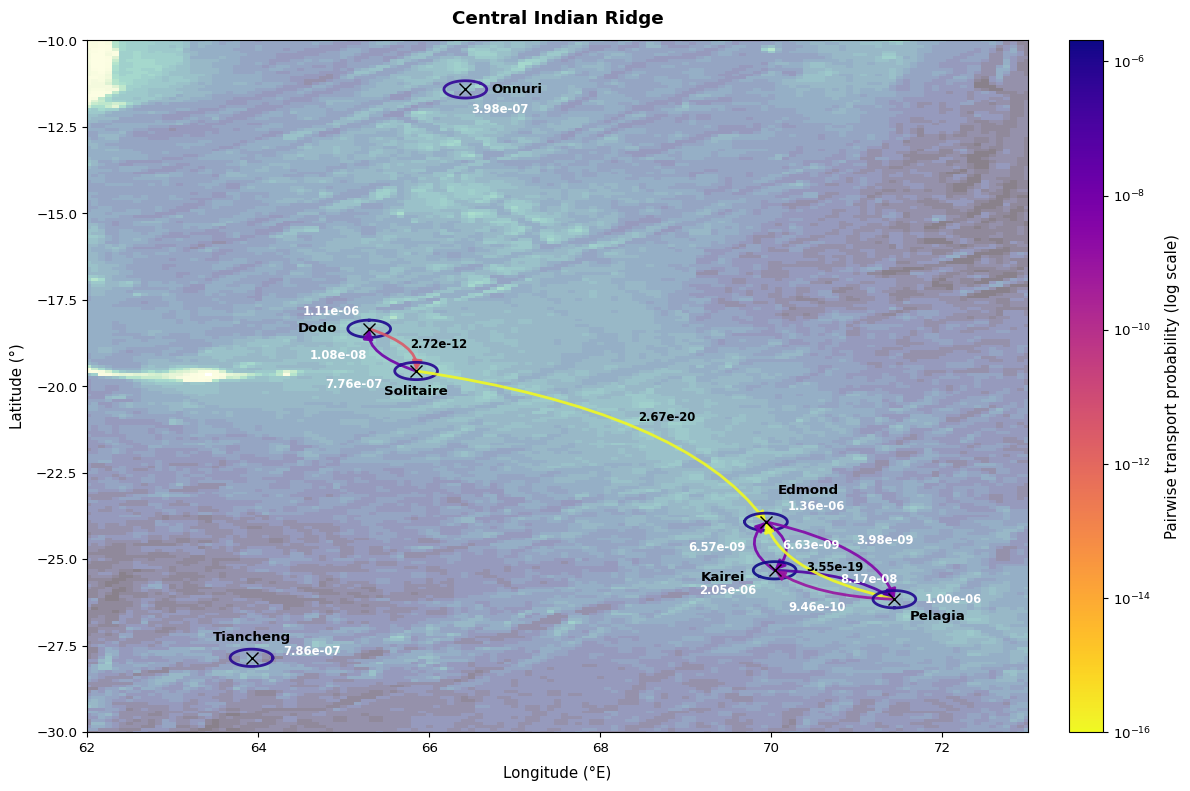

In [25]:

# ===================== CONFIG =====================
font_scale = 1.2
plt.rcParams.update({
    "font.size": 8 * font_scale,
    "axes.titlesize": 10 * font_scale,
    "axes.labelsize": 9 * font_scale,
    "xtick.labelsize": 8 * font_scale,
    "ytick.labelsize": 8 * font_scale,
    "legend.fontsize": 8 * font_scale,
    "figure.titlesize": 12 * font_scale
})

region_bounds = {
    "name": "Central Indian Ridge",
    "lat_min": -30, "lat_max": -10,
    "lon_min": 62, "lon_max": 73
}

# ===================== DATA FILTERING =====================
lon_min, lon_max = region_bounds["lon_min"], region_bounds["lon_max"]
lat_min, lat_max = region_bounds["lat_min"], region_bounds["lat_max"]

vents_used = vent_sites[
    ((vent_sites["Longitude"] % 360) >= lon_min)
    & ((vent_sites["Longitude"] % 360) <= lon_max)
    & (vent_sites["Latitude"] >= lat_min)
    & (vent_sites["Latitude"] <= lat_max)
].copy()

selected = vents_used["name"].astype(str).tolist()
conn_used = prob_conn.loc[selected, selected]

pos = {
    n: ((vents_used.loc[vents_used["name"] == n, "Longitude"].iloc[0] % 360),
        vents_used.loc[vents_used["name"] == n, "Latitude"].iloc[0])
    for n in vents_used["name"]
}

# ===================== COLOR SCALING =====================
vals = conn_used.values
posvals = vals[vals > 0]
use_log = posvals.size and (np.nanmax(vals) / max(np.nanmin(posvals), 1e-30) > 1e4)
norm = LogNorm(vmin=max(posvals.min(), 1e-16), vmax=vals.max()) if use_log \
       else Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))
edge_cmap = plt.cm.plasma_r
sm = ScalarMappable(norm=norm, cmap=edge_cmap)

# ===================== SIMPLE LABEL OFFSETS (NEW) =====================
# Vent NAME labels
name_label_offsets = [
    (0, 0.6), (0.6, 0), (-0.6, 0), (0, -0.6),
    (0.5, 0.9), (-0.6, -0.2), (0.5, -0.5), (-0.5, -0.5)
]

# Curved-arrow VALUE labels
arrow_label_offsets = [
    (0, 0), (0, 0), (0, 0), (0, 0),
    (0, 0), (0, 0), (0, 0), (0, 0), (0,0), (0,0), (0,0), (0,0)
    , (10,0), (10,0), (0,0), (0,0), (0,0), (0.2,0), (10,0), (10,0), (10,0), (10,0)
    , (10,0), (-0.3,0), (10,0), (0.2,0.2), (10,0), (10,0), (10,0), (10,0), (10,0), (10,0)
    , (10,0), (0.1,0), (0.2,0.3), (10,0), (10,0), (10,0), (10,0), (-0.25,0), (10,0), (0.2,-0.2)
    , (10,0), (10,0), (10,0), (10,0), (0.5,0.1), (0,-0.3), (0,0), (0,0), (0,0), (0,0)
]

# Self-loop VALUE labels
loop_label_offsets = [
    (0.3, 0.0), (0.25, -1), (-0.25, 0.1), (-0.3, -0.55),
    (1.0, 0.65), (-0.4, -0.15), (0.5, 0.4)
]

# ===================== DRAWING HELPERS =====================
def curved_arrow(ax, x0, y0, x1, y1, w, color,
                 rad=0.25, lw=2.0, zorder=5,
                 label_dx=0.0, label_dy=0.0):
    """Curved arrow between two vents with midpoint label + simple (dx,dy)."""
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    dx, dy = (x1 - x0), (y1 - y0)
    L = np.hypot(dx, dy) + 1e-12
    px, py = -dy / L, dx / L
    cpx, cpy = cx + rad * px * L, cy + rad * py * L

    path = Path([(x0, y0), (cpx, cpy), (x1, y1)],
                [Path.MOVETO, Path.CURVE3, Path.CURVE3])
    patch = FancyArrowPatch(path=path, arrowstyle="-|>", mutation_scale=14,
                            lw=lw, color=color, alpha=0.9, zorder=zorder)
    ax.add_patch(patch)

    # label midpoint + original perpendicular nudge + simple (dx,dy)
    t = 0.5
    bx = (1 - t)**2 * x0 + 2*(1 - t)*t * cpx + t**2 * x1
    by = (1 - t)**2 * y0 + 2*(1 - t)*t * cpy + t**2 * y1
    bx += 0.2 * px + label_dx
    by += 0.2 * py + label_dy

    label = f"{w:.2e}" if use_log or (w < 1e-3 or w > 1e3) else f"{w:.3f}"
    r, g, b, _ = color
    Lb = 0.2126*r + 0.7152*g + 0.0722*b
    txt = "white" if Lb < 0.4 else "black"
    ax.text(bx, by, label, ha="center", va="center",
            color=txt, fontsize=7 * font_scale, fontweight="bold", zorder=zorder+1)

def draw_self_loop_anchor(ax, x, y, w, color,
                          radius=0.25, lw=2.0, zorder=5, label_index=0,
                          label_dx=0.0, label_dy=0.0):
    """
    Anchored self-loop that starts/ends at (x,y) with label position
    + simple (dx,dy).
    """
    start_angle = np.deg2rad(45 * (label_index % 8))
    theta = np.linspace(start_angle, start_angle + 2 * np.pi, 100)
    xs = x + radius * np.cos(theta)
    ys = y + radius * np.sin(theta)
    ax.plot(xs, ys, color=color, lw=lw, alpha=0.9, zorder=zorder)

    offset_angle = np.deg2rad(45 * (label_index % 8) + 25)
    lx = x + (radius * 1.8) * np.cos(offset_angle) + label_dx
    ly = y + (radius * 1.8) * np.sin(offset_angle) + label_dy

    # keep your current self-loop label formatting
    label = f"{w:.2e}" if w < 1e-3 else f"{w:.3f}"

    r, g, b, _ = color
    Lb = 0.2126*r + 0.7152*g + 0.0722*b
    txt = "white" if Lb < 0.4 else "black"
    ax.text(lx, ly, label, ha="center", va="center",
            fontsize=7 * font_scale, fontweight="bold", color=txt, zorder=zorder+1)

# ===================== MAP BACKGROUND =====================
fig, ax = plt.subplots(figsize=(12, 8))
lon_c = seafloor["longitude"].sel(longitude=slice(lon_min, lon_max)).values
lat_c = seafloor["latitude"].sel(latitude=slice(lat_min, lat_max)).values
Z = seafloor["deptho"].sel(longitude=slice(lon_min, lon_max),
                           latitude=slice(lat_min, lat_max)).compute().values

def edges_from_centers(x):
    dx = np.diff(x)
    left, right = x[0] - dx[0]/2, x[-1] + dx[-1]/2
    return np.concatenate(([left], (x[:-1] + x[1:]) / 2, [right]))

Xe, Ye = np.meshgrid(edges_from_centers(lon_c), edges_from_centers(lat_c))
ax.pcolormesh(Xe, Ye, Z, cmap=cmocean.cm.deep, vmin=0, alpha=0.55, shading="flat", zorder=0)

# ===================== VENTS + EDGES =====================
ax.plot(vents_used["Longitude"] % 360, vents_used["Latitude"],
        "x", color="black", markersize=10 * font_scale/1.5, lw=1.2, zorder=6)

# === Vent NAME labels with simple cycling offsets ===
for idx, row in enumerate(vents_used.itertuples()):
    dx, dy = name_label_offsets[idx % len(name_label_offsets)]
    ax.text((row.Longitude % 360) + dx, row.Latitude + dy,
            row.name, ha="center", va="center",
            fontsize=8 * font_scale, color="black",
            fontweight="bold", zorder=7)

# === Draw connectivity arrows ===
threshold = 1e-21  # Skip very small probabilities

for i, src in enumerate(conn_used.index):
    x0, y0 = pos[src]
    for j, tgt in enumerate(conn_used.columns):
        w = conn_used.at[src, tgt]
        if w <= threshold or not np.isfinite(w):
            continue

        color = sm.to_rgba(w)

        if src == tgt:
            # self-loop VALUE label offsets (cycled)
            ldx, ldy = loop_label_offsets[i % len(loop_label_offsets)]
            draw_self_loop_anchor(ax, x0, y0, w, color,
                                  radius=0.25, lw=2.0,
                                  label_index=i,
                                  label_dx=ldx, label_dy=ldy)
        else:
            x1, y1 = pos[tgt]
            # curved-arrow VALUE label offsets (cycled)
            k = i * len(conn_used.columns) + j
            ldx, ldy = arrow_label_offsets[k % len(arrow_label_offsets)]
            curved_arrow(ax, x0, y0, x1, y1, w, color,
                         rad=0.25, lw=2.0,
                         label_dx=ldx, label_dy=ldy)

# ===================== LAYOUT =====================
cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pairwise transport probability" + (" (log scale)" if use_log else ""),
               fontsize=9 * font_scale, labelpad=10)
cbar.ax.tick_params(labelsize=8 * font_scale)

ax.set_xlim(region_bounds["lon_min"], region_bounds["lon_max"])
ax.set_ylim(region_bounds["lat_min"], region_bounds["lat_max"])
ax.set_xlabel("Longitude (°E)", fontsize=9 * font_scale, labelpad=8)
ax.set_ylabel("Latitude (°)", fontsize=9 * font_scale, labelpad=8)
ax.set_title(f"{region_bounds['name']}",
             fontsize=11 * font_scale, fontweight="bold", pad=12)
ax.tick_params(axis="both", which="major", labelsize=8 * font_scale)

plt.tight_layout()
plt.show()

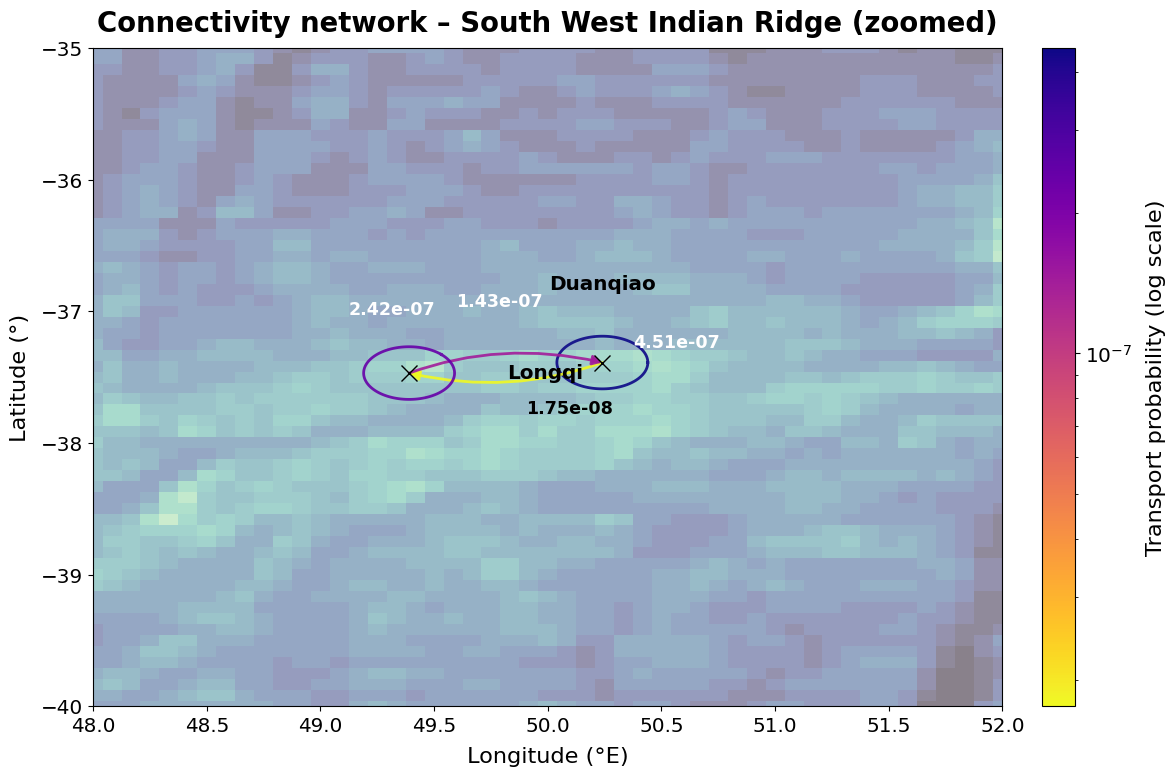

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.patches import FancyArrowPatch
from matplotlib.path import Path
import cmocean

# ===================== CONFIG =====================
font_scale = 1.8
plt.rcParams.update({
    "font.size": 8 * font_scale,
    "axes.titlesize": 10 * font_scale,
    "axes.labelsize": 9 * font_scale,
    "xtick.labelsize": 8 * font_scale,
    "ytick.labelsize": 8 * font_scale,
    "legend.fontsize": 8 * font_scale,
    "figure.titlesize": 12 * font_scale
})

focus_area = True
region_bounds = {
    "name": "South West Indian Ridge (zoomed)",
    "lat_min": -40, "lat_max": -35,
    "lon_min": 48, "lon_max": 52
}

# ===================== DATA FILTERING =====================
if focus_area:
    lon_min, lon_max = region_bounds["lon_min"], region_bounds["lon_max"]
    lat_min, lat_max = region_bounds["lat_min"], region_bounds["lat_max"]
    vents_used = vent_sites[
        ((vent_sites["Longitude"] % 360) >= lon_min)
        & ((vent_sites["Longitude"] % 360) <= lon_max)
        & (vent_sites["Latitude"] >= lat_min)
        & (vent_sites["Latitude"] <= lat_max)
    ].copy()
    selected = vents_used["name"].astype(str).tolist()
    conn_used = prob_conn.loc[selected, selected]
else:
    vents_used = vent_sites.copy()
    conn_used = prob_conn.copy()
    lon_min, lon_max = 48, 52
    lat_min, lat_max = -40, -35

pos = {
    n: ((vents_used.loc[vents_used["name"] == n, "Longitude"].iloc[0] % 360),
        vents_used.loc[vents_used["name"] == n, "Latitude"].iloc[0])
    for n in vents_used["name"]
}

# ===================== COLOR SCALING =====================
vals = conn_used.values
posvals = vals[vals > 0]
use_log = posvals.size and (np.nanmax(vals) / max(np.nanmin(posvals), 1e-30) > 1e4)
#force log
use_log = True
norm = LogNorm(vmin=max(posvals.min(), 1e-16), vmax=vals.max()) if use_log \
       else Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))
edge_cmap = plt.cm.plasma_r
sm = ScalarMappable(norm=norm, cmap=edge_cmap)

# ===================== SIMPLE LABEL OFFSETS (ADD THESE) =====================
# Vent NAME labels
vent_label_offsets = [
    (0, 0.6), (0.6, 0), (-0.6, 0), (0, -0.6),
    (0.5, 0.5), (-0.5, 0.5), (0.5, -0.5), (-0.5, -0.5)
]

# Curved-arrow VALUE labels
arrow_label_offsets = [
    (0, 0), (0.25, 0), (0.0, 0.2), (-0.25, -0.05),
    (0, 0), (-0.5, -0.2), (0.4, 0.2), (-0.15, -0.15)
]

# Self-loop VALUE labels
loop_label_offsets = [
    (0, 0), (-0.2, 0.15), (0.2, 0.15), (0, -0.2),
    (0.25, 0), (-0.25, 0), (0.15, -0.15), (-0.15, -0.15)
]

# ===================== DRAWING HELPERS =====================
def curved_arrow(ax, x0, y0, x1, y1, w, color,
                 rad=0.25, lw=2.0, zorder=5,
                 label_dx=0.0, label_dy=0.0):
    """Curved arrow between two vents + label with simple (dx,dy)."""
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    dx, dy = (x1 - x0), (y1 - y0)
    L = np.hypot(dx, dy) + 1e-12
    px, py = -dy / L, dx / L
    cpx, cpy = cx + rad * px * L, cy + rad * py * L

    path = Path([(x0, y0), (cpx, cpy), (x1, y1)],
                [Path.MOVETO, Path.CURVE3, Path.CURVE3])
    patch = FancyArrowPatch(path=path, arrowstyle="-|>", mutation_scale=14,
                            lw=lw, color=color, alpha=0.9, zorder=zorder)
    ax.add_patch(patch)

    # label at midpoint with contrast (keep your perpendicular nudge + manual offsets)
    t = 0.5
    bx = (1 - t)**2 * x0 + 2*(1 - t)*t * cpx + t**2 * x1
    by = (1 - t)**2 * y0 + 2*(1 - t)*t * cpy + t**2 * y1
    bx += 0.2 * px + label_dx
    by += 0.2 * py + label_dy

    label = f"{w:.2e}" if use_log or (w < 1e-3 or w > 1e3) else f"{w:.3f}"
    r, g, b, _ = color
    Lb = 0.2126*r + 0.7152*g + 0.0722*b
    txt = "white" if Lb < 0.4 else "black"
    ax.text(bx, by, label, ha="center", va="center",
            color=txt, fontsize=7 * font_scale, fontweight="bold", zorder=zorder+1)

def draw_self_loop_anchor(ax, x, y, w, color,
                          radius=0.25, lw=2.0, zorder=5,
                          label_index=0, label_dx=0.0, label_dy=0.0):
    """
    Self-loop that looks like the earlier versions:
    - draw a small full loop (circle-ish) around the vent
    - place label outward + simple (dx,dy)
    """
    # draw a full loop around (x,y)
    start_angle = np.deg2rad(45 * (label_index % 8))
    theta = np.linspace(start_angle, start_angle + 2 * np.pi, 120)
    xs = x + radius * np.cos(theta)
    ys = y + radius * np.sin(theta)
    ax.plot(xs, ys, color=color, lw=lw, alpha=0.9, zorder=zorder)

    # label position outward (same “fan out” idea) + manual offsets
    offset_angle = np.deg2rad(45 * (label_index % 8) + 25)
    lx = x + (radius * 1.8) * np.cos(offset_angle) + label_dx
    ly = y + (radius * 1.8) * np.sin(offset_angle) + label_dy

    label = f"{w:.2e}" if (use_log or (w < 1e-3 or w > 1e3)) else f"{w:.3f}"
    r, g, b, _ = color
    Lb = 0.2126*r + 0.7152*g + 0.0722*b
    txt = "white" if Lb < 0.4 else "black"
    ax.text(lx, ly, label, ha="center", va="center",
            fontsize=7 * font_scale, fontweight="bold",
            color=txt, zorder=zorder+1)

# ===================== MAP BACKGROUND =====================
fig, ax = plt.subplots(figsize=(12, 8))

lon_c = seafloor["longitude"].sel(longitude=slice(lon_min, lon_max)).values
lat_c = seafloor["latitude"].sel(latitude=slice(lat_min, lat_max)).values
Z = seafloor["deptho"].sel(longitude=slice(lon_min, lon_max),
                           latitude=slice(lat_min, lat_max)).compute().values

def edges_from_centers(x):
    dx = np.diff(x)
    left, right = x[0] - dx[0]/2, x[-1] + dx[-1]/2
    return np.concatenate(([left], (x[:-1] + x[1:]) / 2, [right]))

Xe, Ye = np.meshgrid(edges_from_centers(lon_c), edges_from_centers(lat_c))
ax.pcolormesh(Xe, Ye, Z, cmap=cmocean.cm.deep, vmin=0, alpha=0.55, shading="flat", zorder=0)

# ===================== VENTS + EDGES =====================
ax.plot(vents_used["Longitude"] % 360, vents_used["Latitude"],
        "x", color="black", markersize=10 * font_scale/1.5, lw=1.2, zorder=6)

# Vent NAME labels with simple cycling offsets
for idx, row in enumerate(vents_used.itertuples()):
    dx, dy = vent_label_offsets[idx % len(vent_label_offsets)]
    ax.text((row.Longitude % 360) + dx, row.Latitude + dy,
            row.name, ha="center", va="center",
            fontsize=8 * font_scale, color="black",
            fontweight="bold", zorder=7)

# Connectivity edges + VALUE label offsets
for i, src in enumerate(conn_used.index):
    x0, y0 = pos[src]
    for j, tgt in enumerate(conn_used.columns):
        w = conn_used.at[src, tgt]
        if w <= 0:
            continue

        color = sm.to_rgba(w)

        if src == tgt:
            ldx, ldy = loop_label_offsets[i % len(loop_label_offsets)]
            draw_self_loop_anchor(ax, x0, y0, w, color,
                                  radius=0.2, lw=2.0,
                                  label_index=i,
                                  label_dx=ldx, label_dy=ldy)
        else:
            x1, y1 = pos[tgt]
            k = i * len(conn_used.columns) + j
            ldx, ldy = arrow_label_offsets[k % len(arrow_label_offsets)]
            curved_arrow(ax, x0, y0, x1, y1, w, color,
                         rad=0.25, lw=2.0,
                         label_dx=ldx, label_dy=ldy)

# ===================== LAYOUT =====================
cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Transport probability" + (" (log scale)" if use_log else ""),
               fontsize=9 * font_scale, labelpad=10)
cbar.ax.tick_params(labelsize=8 * font_scale)

ax.set_xlim(region_bounds["lon_min"], region_bounds["lon_max"])
ax.set_ylim(region_bounds["lat_min"], region_bounds["lat_max"])
ax.set_xlabel("Longitude (°E)", fontsize=9 * font_scale, labelpad=8)
ax.set_ylabel("Latitude (°)", fontsize=9 * font_scale, labelpad=8)
ax.set_title(f"Connectivity network – {region_bounds['name']}",
             fontsize=11 * font_scale, fontweight="bold", pad=12)
ax.tick_params(axis="both", which="major", labelsize=8 * font_scale)

plt.tight_layout()
plt.show()

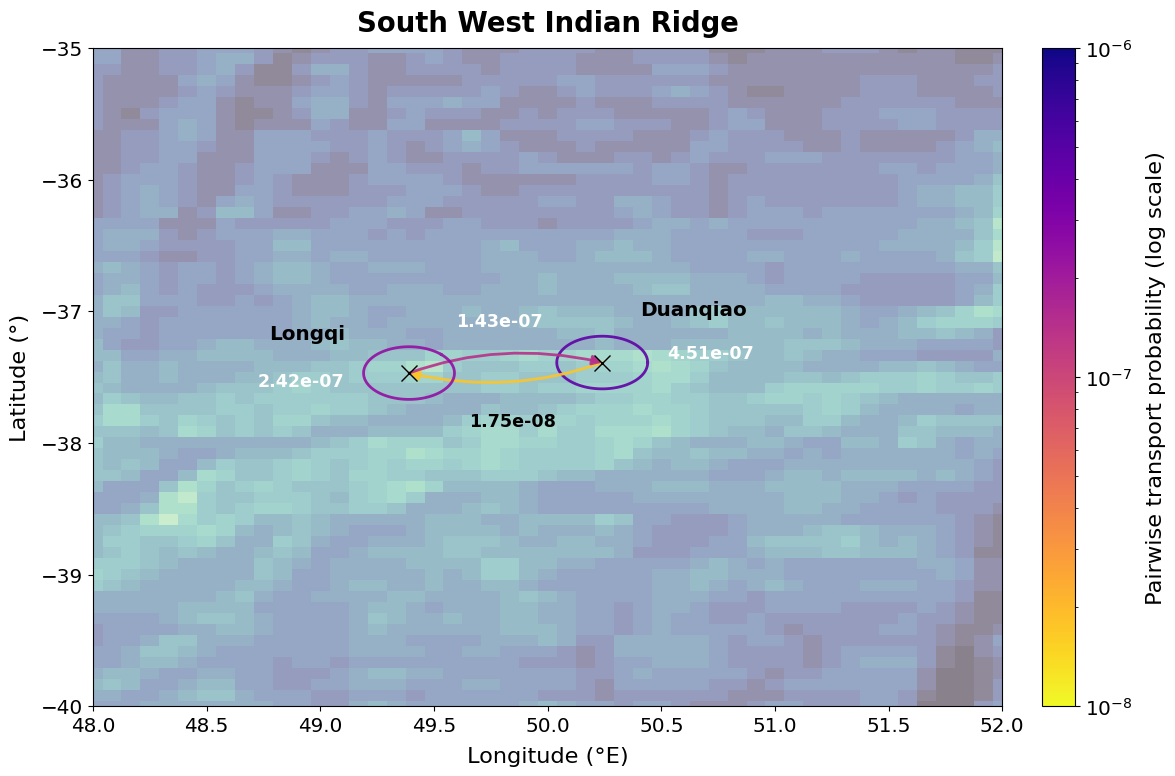

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.patches import FancyArrowPatch
from matplotlib.path import Path
from matplotlib.ticker import LogLocator, LogFormatterSciNotation
import cmocean

# ===================== CONFIG =====================
font_scale = 1.8
plt.rcParams.update({
    "font.size": 8 * font_scale,
    "axes.titlesize": 10 * font_scale,
    "axes.labelsize": 9 * font_scale,
    "xtick.labelsize": 8 * font_scale,
    "ytick.labelsize": 8 * font_scale,
    "legend.fontsize": 8 * font_scale,
    "figure.titlesize": 12 * font_scale
})

focus_area = True
region_bounds = {
    "name": "South West Indian Ridge",
    "lat_min": -40, "lat_max": -35,
    "lon_min": 48, "lon_max": 52
}

# ===================== DATA FILTERING =====================
if focus_area:
    lon_min, lon_max = region_bounds["lon_min"], region_bounds["lon_max"]
    lat_min, lat_max = region_bounds["lat_min"], region_bounds["lat_max"]

    vents_used = vent_sites[
        ((vent_sites["Longitude"] % 360) >= lon_min)
        & ((vent_sites["Longitude"] % 360) <= lon_max)
        & (vent_sites["Latitude"] >= lat_min)
        & (vent_sites["Latitude"] <= lat_max)
    ].copy()

    selected = vents_used["name"].astype(str).tolist()
    conn_used = prob_conn.loc[selected, selected]
else:
    vents_used = vent_sites.copy()
    conn_used = prob_conn.copy()
    lon_min, lon_max = 48, 52
    lat_min, lat_max = -40, -35

pos = {
    n: ((vents_used.loc[vents_used["name"] == n, "Longitude"].iloc[0] % 360),
        vents_used.loc[vents_used["name"] == n, "Latitude"].iloc[0])
    for n in vents_used["name"]
}

# ===================== COLOR SCALING (LOG + FULL DECADES) =====================
vals = conn_used.values
posvals = vals[(vals > 0) & np.isfinite(vals)]

use_log = True  # set False if you want linear

edge_cmap = plt.cm.plasma_r

if use_log:
    vmin_data = max(posvals.min(), 1e-16)
    vmax_data = np.nanmax(posvals)

    # Expand to full decades so 10^-8, 10^-7, 10^-6 ticks are INSIDE the bar
    log_min = int(np.floor(np.log10(vmin_data)))
    log_max = int(np.ceil(np.log10(vmax_data)))

    vmin = 10 ** log_min
    vmax = 10 ** log_max

    norm = LogNorm(vmin=vmin, vmax=vmax)
else:
    norm = Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))

sm = ScalarMappable(norm=norm, cmap=edge_cmap)
sm.set_array([])  # helps colorbar behave consistently

# ===================== SIMPLE LABEL OFFSETS =====================
vent_label_offsets = [
    (0.4, 0.4), (-0.45, 0.3)
]
arrow_label_offsets = [
    (0, 0.05), (0.0, -0.1)
]
loop_label_offsets = [
    (0.15, -0.08), (-0.6, -0.4)
]

# ===================== DRAWING HELPERS =====================
def curved_arrow(ax, x0, y0, x1, y1, w, color,
                 rad=0.25, lw=2.0, zorder=5,
                 label_dx=0.0, label_dy=0.0):
    """Curved arrow + value label (with simple offsets)."""
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    dx, dy = (x1 - x0), (y1 - y0)
    L = np.hypot(dx, dy) + 1e-12
    px, py = -dy / L, dx / L
    cpx, cpy = cx + rad * px * L, cy + rad * py * L

    path = Path([(x0, y0), (cpx, cpy), (x1, y1)],
                [Path.MOVETO, Path.CURVE3, Path.CURVE3])
    patch = FancyArrowPatch(path=path, arrowstyle="-|>", mutation_scale=14,
                            lw=lw, color=color, alpha=0.9, zorder=zorder)
    ax.add_patch(patch)

    t = 0.5
    bx = (1 - t)**2 * x0 + 2*(1 - t)*t * cpx + t**2 * x1
    by = (1 - t)**2 * y0 + 2*(1 - t)*t * cpy + t**2 * y1
    bx += 0.2 * px + label_dx
    by += 0.2 * py + label_dy

    label = f"{w:.2e}" if use_log or (w < 1e-3 or w > 1e3) else f"{w:.3f}"
    r, g, b, _ = color
    Lb = 0.2126*r + 0.7152*g + 0.0722*b
    txt = "white" if Lb < 0.4 else "black"
    ax.text(bx, by, label, ha="center", va="center",
            color=txt, fontsize=7 * font_scale, fontweight="bold", zorder=zorder+1)

def draw_self_loop_anchor(ax, x, y, w, color,
                          radius=0.25, lw=2.0, zorder=5,
                          label_index=0, label_dx=0.0, label_dy=0.0):
    """Circular self-loop (matches your other scripts) + label offsets."""
    start_angle = np.deg2rad(45 * (label_index % 8))
    theta = np.linspace(start_angle, start_angle + 2 * np.pi, 120)
    xs = x + radius * np.cos(theta)
    ys = y + radius * np.sin(theta)
    ax.plot(xs, ys, color=color, lw=lw, alpha=0.9, zorder=zorder)

    offset_angle = np.deg2rad(45 * (label_index % 8) + 25)
    lx = x + (radius * 1.8) * np.cos(offset_angle) + label_dx
    ly = y + (radius * 1.8) * np.sin(offset_angle) + label_dy

    label = f"{w:.2e}" if use_log or (w < 1e-3 or w > 1e3) else f"{w:.3f}"
    r, g, b, _ = color
    Lb = 0.2126*r + 0.7152*g + 0.0722*b
    txt = "white" if Lb < 0.4 else "black"
    ax.text(lx, ly, label, ha="center", va="center",
            fontsize=7 * font_scale, fontweight="bold", color=txt, zorder=zorder+1)

# ===================== MAP BACKGROUND =====================
fig, ax = plt.subplots(figsize=(12, 8))

lon_c = seafloor["longitude"].sel(longitude=slice(lon_min, lon_max)).values
lat_c = seafloor["latitude"].sel(latitude=slice(lat_min, lat_max)).values
Z = seafloor["deptho"].sel(longitude=slice(lon_min, lon_max),
                           latitude=slice(lat_min, lat_max)).compute().values

def edges_from_centers(x):
    dx = np.diff(x)
    left, right = x[0] - dx[0]/2, x[-1] + dx[-1]/2
    return np.concatenate(([left], (x[:-1] + x[1:]) / 2, [right]))

Xe, Ye = np.meshgrid(edges_from_centers(lon_c), edges_from_centers(lat_c))
ax.pcolormesh(Xe, Ye, Z, cmap=cmocean.cm.deep, vmin=0, alpha=0.55, shading="flat", zorder=0)

# ===================== VENTS =====================
ax.plot(vents_used["Longitude"] % 360, vents_used["Latitude"],
        "x", color="black", markersize=10 * font_scale/1.5, lw=1.2, zorder=6)

for idx, row in enumerate(vents_used.itertuples()):
    dx, dy = vent_label_offsets[idx % len(vent_label_offsets)]
    ax.text((row.Longitude % 360) + dx, row.Latitude + dy,
            row.name, ha="center", va="center",
            fontsize=8 * font_scale, color="black",
            fontweight="bold", zorder=7)

# ===================== EDGES + VALUE LABELS =====================
for i, src in enumerate(conn_used.index):
    x0, y0 = pos[src]
    for j, tgt in enumerate(conn_used.columns):
        w = conn_used.at[src, tgt]
        if w <= 0 or not np.isfinite(w):
            continue

        color = sm.to_rgba(w)

        if src == tgt:
            ldx, ldy = loop_label_offsets[i % len(loop_label_offsets)]
            draw_self_loop_anchor(ax, x0, y0, w, color,
                                  radius=0.2, lw=2.0,
                                  label_index=i,
                                  label_dx=ldx, label_dy=ldy)
        else:
            x1, y1 = pos[tgt]
            k = i * len(conn_used.columns) + j
            ldx, ldy = arrow_label_offsets[k % len(arrow_label_offsets)]
            curved_arrow(ax, x0, y0, x1, y1, w, color,
                         rad=0.25, lw=2.0,
                         label_dx=ldx, label_dy=ldy)

# ===================== COLORBAR (LOG TICKS INSIDE NORM RANGE) =====================
cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)

if use_log:
    # ticks at each decade covered by the (expanded) norm range
    ticks = np.logspace(log_min, log_max, log_max - log_min + 1)
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([rf"$10^{{{k}}}$" for k in range(log_min, log_max + 1)])

cbar.set_label("Pairwise transport probability" + (" (log scale)" if use_log else ""),
               fontsize=9 * font_scale, labelpad=10)
cbar.ax.tick_params(labelsize=8 * font_scale)

# ===================== AXES =====================
ax.set_xlim(region_bounds["lon_min"], region_bounds["lon_max"])
ax.set_ylim(region_bounds["lat_min"], region_bounds["lat_max"])
ax.set_xlabel("Longitude (°E)", fontsize=9 * font_scale, labelpad=8)
ax.set_ylabel("Latitude (°)", fontsize=9 * font_scale, labelpad=8)
ax.set_title(f"{region_bounds['name']}",
             fontsize=11 * font_scale, fontweight="bold", pad=12)
ax.tick_params(axis="both", which="major", labelsize=8 * font_scale)

plt.tight_layout()
plt.show()